# Kerning AVATAR in Inter

Every glyph in a font has an advance width: how far the pen moves after drawing it. Placing glyphs one advance after another leaves awkward gaps between letters like A and V. Kerning fixes this: the font stores an adjustment for specific pairs of glyphs, and the layout engine adds it to the advance.

This notebook reads the advances and the kerning pairs from Inter Regular's `hmtx` and `GPOS` tables with fontTools, then draws AVATAR with and without kerning in BrushCue. A box around each letter shows its advance.

In [1]:
import os
from pathlib import Path

import brushcue

def find_repo_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "writing/graphics/fonts").is_dir():
            return directory
    raise FileNotFoundError("Could not find the graphics book directory")

# BrushCue reads files relative to the working directory, so run from the
# monorepo root to load the fonts stored in the repository.
os.chdir(find_repo_root())
ctx = brushcue.Context()

# The static Regular cut has its overlapping contours merged, which BrushCue
# needs to fill glyphs like "A" correctly.
INTER_PATH = "writing/graphics/fonts/Inter-Regular.ttf"
BOOK_FONT_PATH = "writing/graphics/fonts/LibertinusSerif-Regular.otf"
TEXT = "AVATAR"

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


In [2]:
from fontTools.ttLib import TTFont

inter = TTFont(INTER_PATH)
UNITS_PER_EM = inter["head"].unitsPerEm
ASCENT = inter["hhea"].ascent
DESCENT = -inter["hhea"].descent
glyph_names = {character: inter.getBestCmap()[ord(character)] for character in set(TEXT)}
advances = {character: inter["hmtx"][name][0] for character, name in glyph_names.items()}

gpos = inter["GPOS"].table
kern_lookup_indices = sorted({
    index
    for record in gpos.FeatureList.FeatureRecord
    if record.FeatureTag == "kern"
    for index in record.Feature.LookupListIndex
})

def kern_value(first, second):
    """The x advance adjustment the font's kern feature applies to the pair."""
    first, second = glyph_names[first], glyph_names[second]
    for lookup_index in kern_lookup_indices:
        lookup = gpos.LookupList.Lookup[lookup_index]
        for subtable in lookup.SubTable:
            if lookup.LookupType == 9:
                # Extension lookups wrap the real subtable.
                subtable = subtable.ExtSubTable
            if subtable.LookupType != 2 or first not in subtable.Coverage.glyphs:
                continue
            value = None
            if subtable.Format == 1:
                # Format 1 lists each second glyph explicitly.
                pair_set = subtable.PairSet[subtable.Coverage.glyphs.index(first)]
                for record in pair_set.PairValueRecord:
                    if record.SecondGlyph == second:
                        value = record.Value1
            else:
                # Format 2 groups glyphs into classes and stores one value per class pair.
                first_class = subtable.ClassDef1.classDefs.get(first, 0)
                second_class = subtable.ClassDef2.classDefs.get(second, 0)
                value = subtable.Class1Record[first_class].Class2Record[second_class].Value1
            if value is not None and getattr(value, "XAdvance", 0):
                return value.XAdvance
    return 0

print(f"units per em: {UNITS_PER_EM}, ascent: {ASCENT}, descent: {DESCENT}")
for character in sorted(advances):
    print(f"advance {character}: {advances[character]}")
for first, second in zip(TEXT, TEXT[1:]):
    print(f"kern {first}{second}: {kern_value(first, second)}")

units per em: 2048, ascent: 1984, descent: 494
advance A: 1413
advance R: 1318
advance T: 1322
advance V: 1413
kern AV: -140
kern VA: -140
kern AT: -174
kern TA: -174
kern AR: 0


In [3]:
def layout(text, kerned):
    """(character, pen x, advance) for each character, in font units."""
    placed = []
    pen_x = 0
    for index, character in enumerate(text):
        placed.append((character, pen_x, advances[character]))
        pen_x += advances[character]
        if kerned and index + 1 < len(text):
            pen_x += kern_value(character, text[index + 1])
    return placed

UNKERNED = layout(TEXT, kerned=False)
KERNED = layout(TEXT, kerned=True)
print("unkerned width:", UNKERNED[-1][1] + UNKERNED[-1][2])
print("kerned width:", KERNED[-1][1] + KERNED[-1][2])

unkerned width: 8292
kerned width: 7664


In [4]:
def solid(r, g, b, a=1.0):
    return brushcue.ProfiledColor.from_rgba_srgb(brushcue.RGBAColor.from_components(r, g, b, a))

INTER = brushcue.Font.from_path(INTER_PATH)
BOOK_FONT = brushcue.Font.from_path(BOOK_FONT_PATH)

SIZE = 400
SCALE = SIZE / UNITS_PER_EM
LINE_HEIGHT = (ASCENT + DESCENT) * SCALE
LABEL_SIZE = 44
LABEL_GAP = 24
MARGIN = 40

TEXT_COLOR = solid(0.15, 0.15, 0.15)
BOX_COLORS = ((0.12, 0.37, 0.75), (0.85, 0.45, 0.1))
GLYPH_STYLE = brushcue.RenderStyle.fill_only(brushcue.Fill.solid(TEXT_COLOR))
IDENTITY = brushcue.Transform2.identity().to_list()

def styled_string(text, font, size, origin, render_style):
    @brushcue.brushcue_fn
    def style_character(character):
        return brushcue.StyledCharacter.new(character, font, size, render_style)

    characters = brushcue.String(brushcue.input_parsers.parse_string_graph(text)).to_character_list()
    return brushcue.StyledString.styled_string_from_characters_free(
        characters.to_stream().map(style_character).collect(),
        brushcue.Point2f.from_components(*origin),
    )

def add_rectangle(painter, left, top, width, height, render_style):
    return painter.add_rectangle_with_render_style(
        brushcue.Point2f.from_components(left + width / 2, top + height / 2),
        brushcue.Vector2f.from_components(width, height),
        0,
        render_style,
        IDENTITY,
    )

def add_centered_label(painter, text, center_x, top):
    # Measure the label at the origin so it can be centered under the overlap.
    label_style = brushcue.RenderStyle.fill_only(brushcue.Fill.solid(TEXT_COLOR))
    bounds = brushcue.Composition.painter(
        brushcue.Painter.new().add_styled_text(styled_string(text, BOOK_FONT, LABEL_SIZE, (0, 0), label_style))
    ).bounds().execute(ctx)
    origin = (center_x - bounds.x - bounds.width / 2, top - bounds.y)
    return painter.add_styled_text(styled_string(text, BOOK_FONT, LABEL_SIZE, origin, label_style))

# Both figures share one canvas, sized to the wider unkerned layout, so they
# appear at the same scale in the book.
CANVAS_WIDTH = (UNKERNED[-1][1] + UNKERNED[-1][2]) * SCALE
CANVAS_HEIGHT = LINE_HEIGHT + LABEL_GAP + LABEL_SIZE * 1.5

def draw(placed, label_kerning):
    painter = add_rectangle(
        brushcue.Painter.new(),
        -MARGIN,
        -MARGIN,
        CANVAS_WIDTH + 2 * MARGIN,
        CANVAS_HEIGHT + 2 * MARGIN,
        brushcue.RenderStyle.fill_only(brushcue.Fill.solid(solid(1, 1, 1, 0))),
    )

    # Advance boxes first, so the letters sit on top of them. Overlapping
    # translucent fills show up as a darker band.
    for index, (character, pen_x, advance) in enumerate(placed):
        r, g, b = BOX_COLORS[index % 2]
        box_style = brushcue.RenderStyle.brush_and_fill(
            brushcue.Brush.solid(solid(r, g, b), 2),
            brushcue.Fill.solid(solid(r, g, b, 0.18)),
        )
        painter = add_rectangle(painter, pen_x * SCALE, 0, advance * SCALE, LINE_HEIGHT, box_style)

    # Each letter is its own string, so BrushCue does not kern it against its
    # neighbors and the layout above decides the spacing.
    for character, pen_x, advance in placed:
        painter = painter.add_styled_text(styled_string(character, INTER, SIZE, (pen_x * SCALE, 0), GLYPH_STYLE))

    if label_kerning:
        for (first, pen_x, advance), (second, next_pen_x, _) in zip(placed, placed[1:]):
            kern = kern_value(first, second)
            if kern == 0:
                continue
            overlap_center = (next_pen_x + pen_x + advance) / 2 * SCALE
            painter = add_centered_label(painter, f"{kern:+d}".replace("-", "−"), overlap_center, LINE_HEIGHT + LABEL_GAP)
    return painter

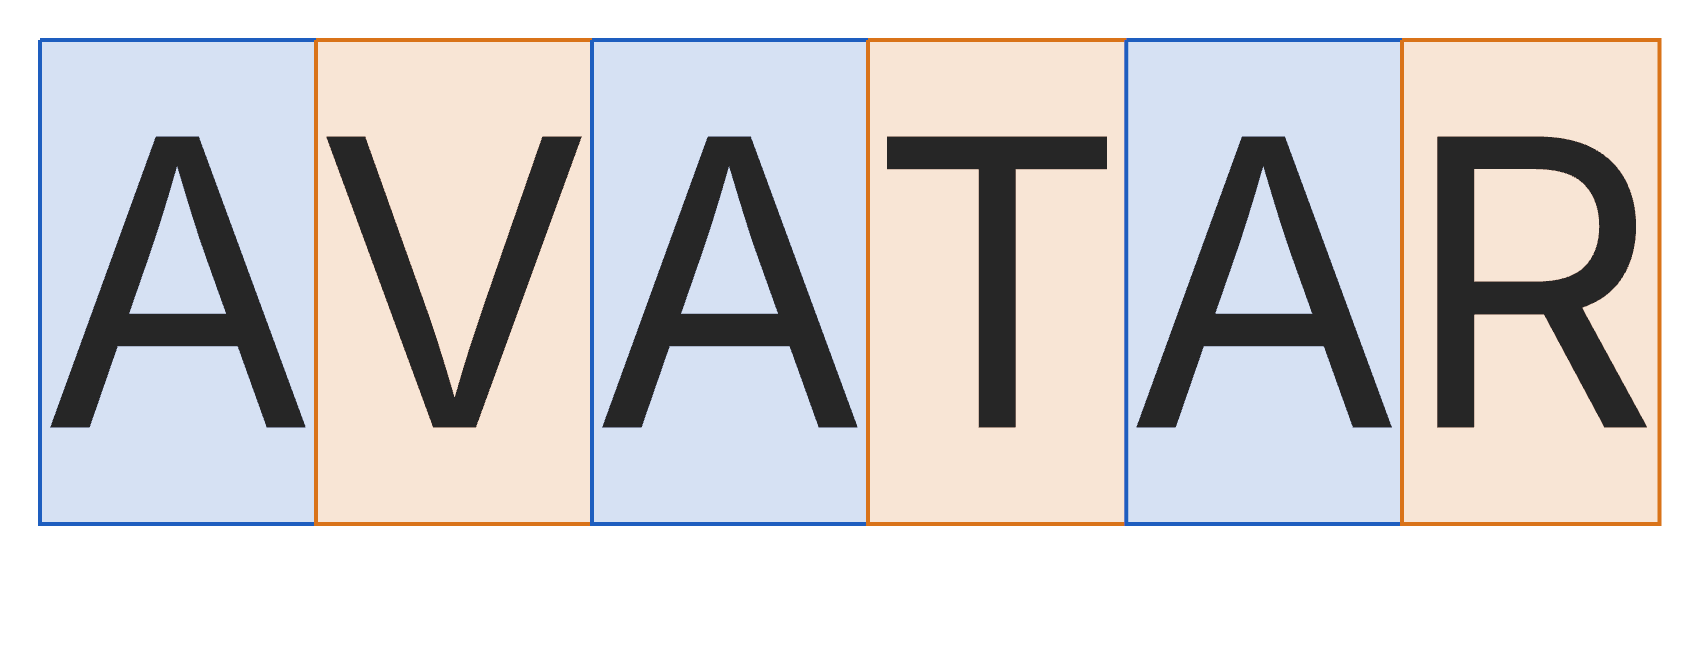

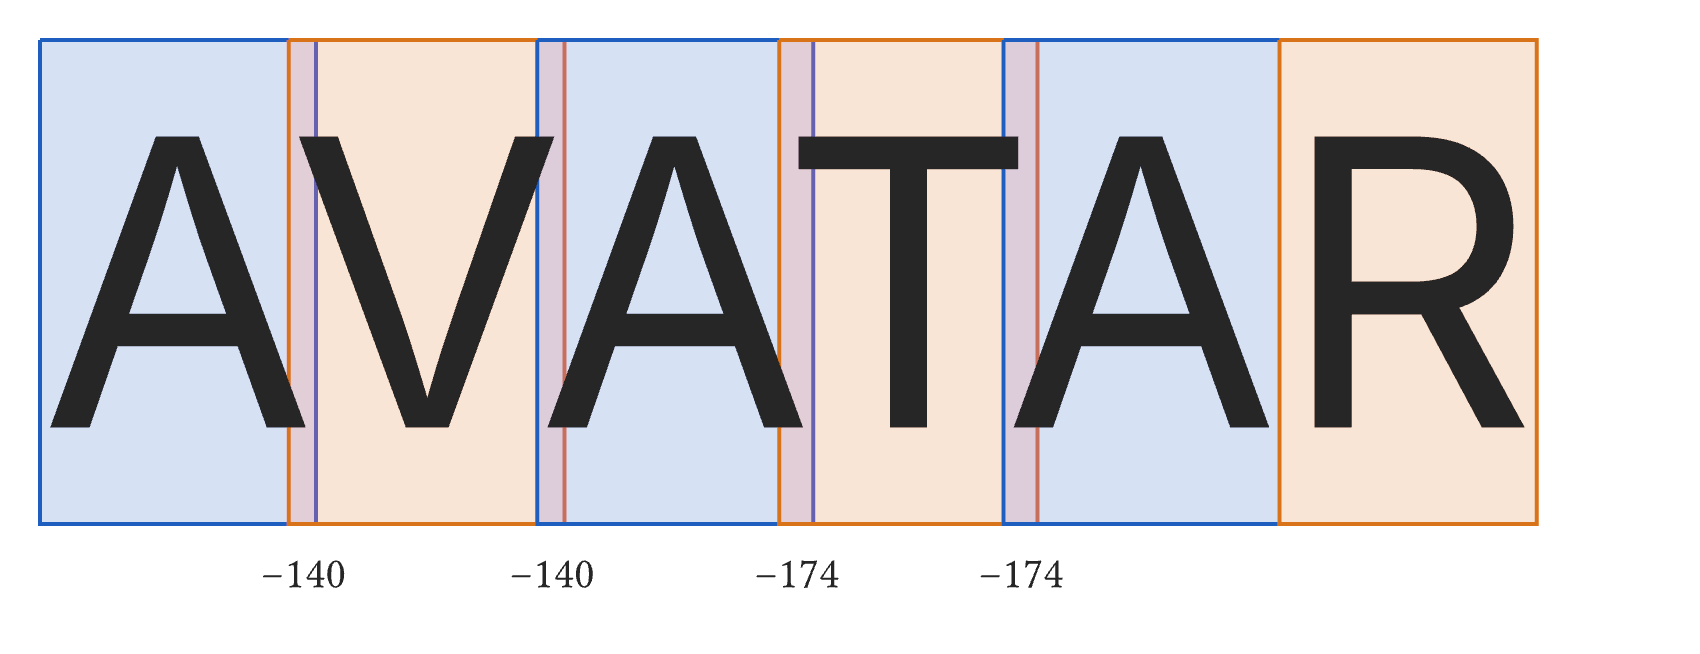

In [5]:
from IPython.display import Image, display

# The working directory is the monorepo root (see the setup cell above).
OUTPUT_DIRECTORY = Path("writing/graphics/chapters/font/assets/avatar-kerning")

def save_figure(painter, name):
    image_bytes = brushcue.Composition.painter(painter).execute(ctx).to_image_bytes(ctx)
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIRECTORY / f"{name}.png").write_bytes(image_bytes)
    display(Image(image_bytes))

save_figure(draw(UNKERNED, label_kerning=False), "avatar_unkerned")
save_figure(draw(KERNED, label_kerning=True), "avatar_kerned")

## Checking against BrushCue's own kerning

BrushCue shapes a run of text with HarfBuzz's rules, which apply the font's kerning automatically. If the values read above are right, AVATAR drawn as a single string should land exactly where the manually kerned letters do.

In [6]:
def ink_bounds(painter):
    return brushcue.Composition.painter(painter).bounds().execute(ctx)

shaped = ink_bounds(brushcue.Painter.new().add_styled_text(styled_string(TEXT, INTER, SIZE, (0, 0), GLYPH_STYLE)))

manual = brushcue.Painter.new()
for character, pen_x, advance in KERNED:
    manual = manual.add_styled_text(styled_string(character, INTER, SIZE, (pen_x * SCALE, 0), GLYPH_STYLE))
manual = ink_bounds(manual)

print("BrushCue kerned:", shaped)
print("Manual kerned:  ", manual)
assert abs(shaped.x - manual.x) <= 1 and abs(shaped.width - manual.width) <= 1

BrushCue kerned: Bounds(x=0, y=0, width=1484.765625, height=387.5)
Manual kerned:   Bounds(x=0, y=0, width=1484.765625, height=387.5)
